# 02 - Analisi statistica: insolventi vs non insolventi

**Progetto:** Credit Risk Scorecard - *Give Me Some Credit*

Confrontiamo il gruppo che va in insolvenza entro 2 anni (`SeriousDlqin2yrs = 1`) con quello che
non va in insolvenza (`= 0`) su 5 variabili: `age`, `MonthlyIncome`,
`RevolvingUtilizationOfUnsecuredLines`, `DebtRatio`, `NumberOfOpenCreditLinesAndLoans`.

Per ciascuna variabile:

1. Verifichiamo la forma della distribuzione (skewness, Shapiro-Wilk su campione, Levene)
2. Scegliamo il test appropriato (t-test di Welch oppure Mann-Whitney U) e motiviamo la scelta
3. Calcoliamo l'**effect size** (Cohen's d o correlazione rank-biserial), non solo il p-value
4. Calcoliamo l'**intervallo di confidenza al 95%** sulla differenza tra i due gruppi

Infine applichiamo la correzione di **Benjamini-Hochberg** per confronti multipli (5 test
contemporanei) e costruiamo una tabella riassuntiva che distingue le differenze *statisticamente
significative* da quelle anche *praticamente rilevanti* — con ~150.000 osservazioni, differenze
banali possono risultare "significative" solo per la numerosità del campione.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Palette del progetto (coerente con il notebook 01_eda)
COLOR_GOOD = '#0ca30c'
COLOR_CRITICAL = '#d03b3b'
GRID_COLOR = '#e1e0d9'
TEXT_COLOR = '#0b0b0b'
MUTED_COLOR = '#898781'

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': GRID_COLOR,
    'axes.grid': True,
    'grid.color': GRID_COLOR,
    'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'text.color': TEXT_COLOR,
    'axes.labelcolor': TEXT_COLOR,
    'xtick.color': MUTED_COLOR,
    'ytick.color': MUTED_COLOR,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

VARIABLES = [
    'age',
    'MonthlyIncome',
    'RevolvingUtilizationOfUnsecuredLines',
    'DebtRatio',
    'NumberOfOpenCreditLinesAndLoans',
]

## 1. Caricamento dataset pulito

Carichiamo l'output del notebook `01_eda` (`data/processed/cs-training-clean.csv`), già privo di
missing e con gli outlier trattati, e separiamo i due gruppi in confronto.

In [2]:
PROJECT_ROOT = Path.cwd().resolve().parents[1]
CLEAN_PATH = PROJECT_ROOT / 'data' / 'processed' / 'cs-training-clean.csv'

df = pd.read_csv(CLEAN_PATH, index_col=0)

g1 = df.loc[df['SeriousDlqin2yrs'] == 1]   # insolventi
g0 = df.loc[df['SeriousDlqin2yrs'] == 0]   # non insolventi

print(f"Insolventi (1):     {len(g1):,} ({len(g1) / len(df) * 100:.2f}%)")
print(f"Non insolventi (0): {len(g0):,} ({len(g0) / len(df) * 100:.2f}%)")

Insolventi (1):     10,026 (6.68%)
Non insolventi (0): 139,973 (93.32%)


## 2. Confronto descrittivo tra i due gruppi

In [3]:
desc_rows = []
for var in VARIABLES:
    desc_rows.append({
        'variabile': var,
        'media_non_insolventi': g0[var].mean(),
        'media_insolventi': g1[var].mean(),
        'mediana_non_insolventi': g0[var].median(),
        'mediana_insolventi': g1[var].median(),
        'std_non_insolventi': g0[var].std(),
        'std_insolventi': g1[var].std(),
    })
desc_df = pd.DataFrame(desc_rows).set_index('variabile').round(3)
desc_df

,media_non_insolventi,media_insolventi,mediana_non_insolventi,mediana_insolventi,std_non_insolventi,std_insolventi
variabile,,,,,,
age,52.752,45.927,52.000,45.000,14.790,12.916
MonthlyIncome,6495.809,5568.825,5500.000,4950.000,13261.427,5659.495
RevolvingUtilizationOfUnsecuredLines,0.294,0.690,0.133,0.839,0.336,0.361
DebtRatio,320.782,257.485,0.363,0.428,910.979,846.815
NumberOfOpenCreditLinesAndLoans,8.494,7.882,8.000,7.000,5.105,5.654


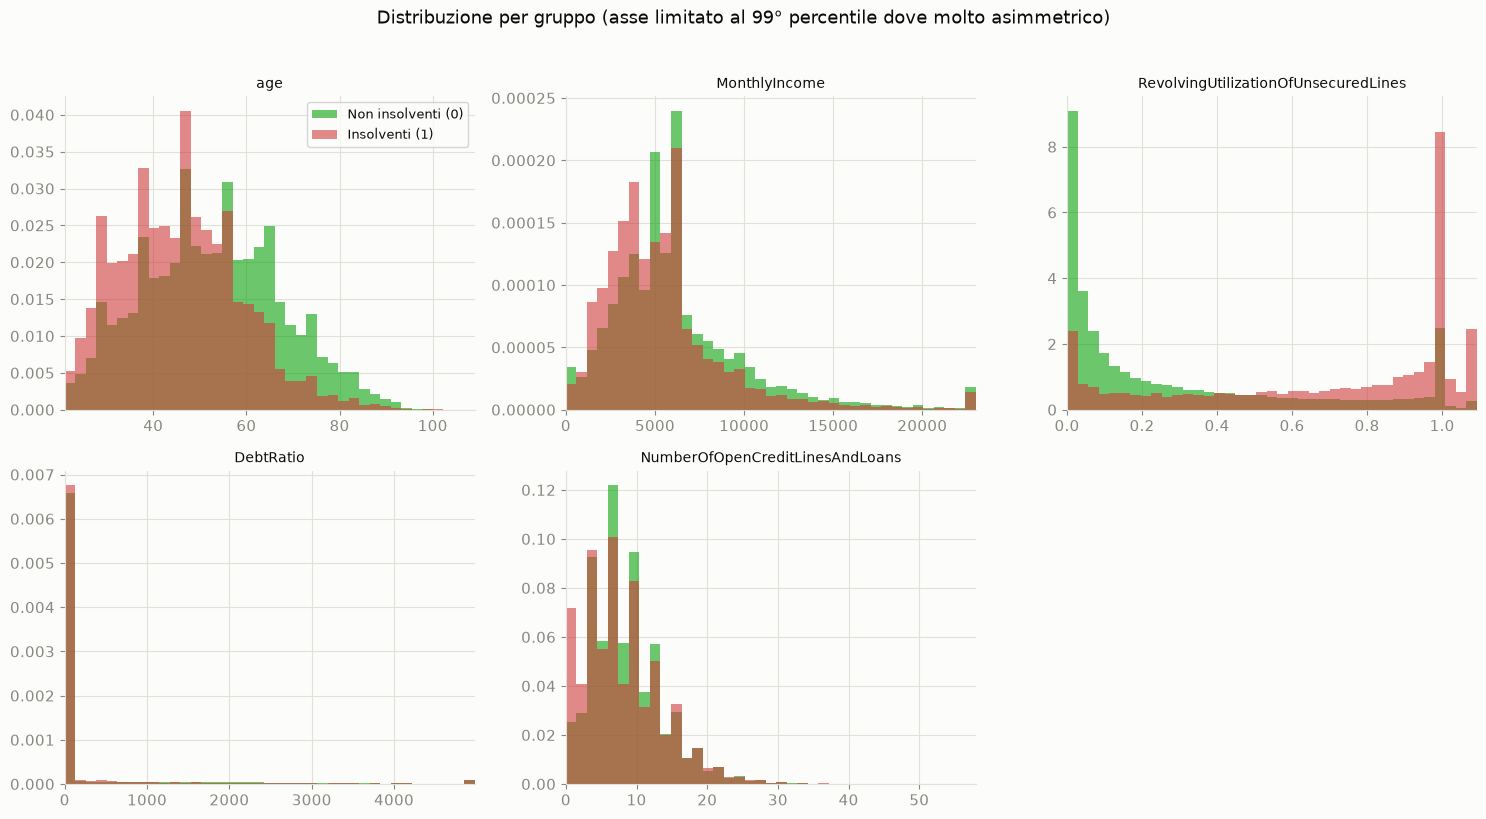

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

# per le variabili molto asimmetriche limitiamo l'asse x al 99° percentile
# SOLO per leggibilità del grafico: i test statistici usano i dati completi.
xlim_99 = {'MonthlyIncome', 'DebtRatio'}

for ax, var in zip(axes, VARIABLES):
    xmax = df[var].quantile(0.99) if var in xlim_99 else df[var].max()
    bins = np.linspace(df[var].min(), xmax, 40)
    ax.hist(g0[var].clip(upper=xmax), bins=bins, density=True, alpha=0.6,
            color=COLOR_GOOD, label='Non insolventi (0)')
    ax.hist(g1[var].clip(upper=xmax), bins=bins, density=True, alpha=0.6,
            color=COLOR_CRITICAL, label='Insolventi (1)')
    ax.set_title(var, fontsize=10)
    ax.set_xlim(df[var].min(), xmax)

axes[0].legend(fontsize=9)
axes[-1].axis('off')
fig.suptitle('Distribuzione per gruppo (asse limitato al 99° percentile dove molto asimmetrico)', y=1.02)
plt.tight_layout()
plt.show()

## 3. Forma della distribuzione: skewness, Shapiro-Wilk, Levene

**Perché un campione per Shapiro-Wilk:** con ~150.000 osservazioni il test di Shapiro-Wilk (come
qualunque test di normalità) rifiuta l'ipotesi nulla quasi per definizione, perché la sua potenza
statistica cresce con *n* e finisce per rilevare anche scostamenti dalla normalità del tutto
trascurabili nella pratica. Per avere una lettura più informativa lo calcoliamo su un campione
casuale di 4.000 osservazioni (seed fissato per riproducibilità) — comunque abbastanza grande da
essere stabile, ma non talmente grande da rendere il test significativo per costruzione.

**Soglia di asimmetria:** consideriamo una distribuzione "fortemente asimmetrica" quando
|skewness| > 0.8, calcolata sull'intera colonna (soglia leggermente più prudente del classico ±1,
adottata *a priori* qui sotto e non aggiustata sui risultati, proprio perché il test t si basa
sulla media, che con una singola coda lunga residua può risultare poco rappresentativa anche
quando il campione è enorme — lo vediamo concretamente più avanti con `DebtRatio`).

**Levene:** verifica l'uguaglianza delle varianze tra i due gruppi. Se rifiutata, usiamo la
variante di **Welch** del t-test (non assume varianze uguali) invece dello Student t-test
classico — scelta comunque ragionevole di default qui, viste le dimensioni molto diverse dei due
gruppi (139.973 vs 10.026).

In [5]:
SKEW_THRESHOLD = 0.8
SHAPIRO_SAMPLE_SIZE = 4000

diag_rows = []
for var in VARIABLES:
    skew_pooled = stats.skew(df[var])
    skew_g0 = stats.skew(g0[var])
    skew_g1 = stats.skew(g1[var])

    sample = rng.choice(df[var].values, size=SHAPIRO_SAMPLE_SIZE, replace=False)
    shapiro_stat, shapiro_p = stats.shapiro(sample)

    levene_stat, levene_p = stats.levene(g0[var], g1[var])

    diag_rows.append({
        'variabile': var,
        'skew_pooled': skew_pooled,
        'skew_non_insolventi': skew_g0,
        'skew_insolventi': skew_g1,
        'shapiro_p (n=4000)': shapiro_p,
        'levene_p': levene_p,
        'test_scelto': 'Mann-Whitney U' if abs(skew_pooled) > SKEW_THRESHOLD else "t-test di Welch",
    })

diag_df = pd.DataFrame(diag_rows).set_index('variabile')
pd.set_option('display.float_format', lambda x: f'{x:.4g}')
diag_df

,skew_pooled,skew_non_insolventi,skew_insolventi,shapiro_p (n=4000),levene_p,test_scelto
variabile,,,,,,
age,0.1892,0.1639,0.4577,1.157e-15,9.365e-85,t-test di Welch
MonthlyIncome,127,125,18,5.834e-83,0.006291,Mann-Whitney U
RevolvingUtilizationOfUnsecuredLines,0.9044,1.044,-0.6934,6.24e-56,7.075e-57,Mann-Whitney U
DebtRatio,3.351,3.315,3.953,9.266e-79,1.434e-11,Mann-Whitney U
NumberOfOpenCreditLinesAndLoans,1.215,1.223,1.194,2.756e-41,2.387e-43,Mann-Whitney U


**Lettura della tabella.** Solo `age` resta sotto la soglia di 0,8 (skewness pooled ≈ 0,19): è
l'unica variabile per cui procediamo con il t-test. Le altre quattro superano la soglia, incluse
`RevolvingUtilizationOfUnsecuredLines` (0,90, alla soglia — coerente con l'attesa iniziale) e
**`NumberOfOpenCreditLinesAndLoans` (1,22)**, che non era stata segnalata come probabile candidata
ma lo è altrettanto: è una variabile di conteggio con coda lunga a destra, e i dati lo confermano.
Il p-value di Shapiro-Wilk è praticamente zero per tutte e 5 le variabili (compresa `age`): anche
una skewness moderata come 0,19 basta a far rifiutare la normalità esatta su un campione di 4.000
righe, il che conferma perché usiamo la skewness (una misura di *quanto* la distribuzione si
discosta dalla simmetria) come criterio di scelta del test, non il solo esito binario di Shapiro-Wilk.
Levene rifiuta l'uguaglianza delle varianze per tutte le variabili (p ben sotto 0,05): il t-test di
Welch per `age` è quindi la scelta corretta, non lo Student t-test classico.

## 4. Test statistici, effect size e intervalli di confidenza

- **t-test di Welch**: effect size = **Cohen's d** (con deviazione standard pooled); IC 95% sulla
  differenza delle medie calcolato analiticamente (formula di Welch-Satterthwaite, via
  `scipy.stats.ttest_ind(...).confidence_interval()`).
- **Mann-Whitney U**: effect size = **correlazione rank-biserial**
  (`r = 2*U/(n1*n2) - 1`, dove U è la statistica calcolata sul gruppo insolventi: r>0 indica valori
  tipicamente più alti tra gli insolventi); IC 95% sulla **differenza delle mediane** stimato con
  **bootstrap percentile** (2.000 ricampionamenti, seed fissato), perché per campioni di queste
  dimensioni non esiste una formula chiusa altrettanto semplice del caso t-test.

Entrambi gli effect size si interpretano con le convenzioni standard (Cohen 1988 e estensioni per
r): trascurabile / piccolo / medio / grande.

In [6]:
def cohens_d(x1, x0):
    n1, n0 = len(x1), len(x0)
    v1, v0 = np.var(x1, ddof=1), np.var(x0, ddof=1)
    pooled_sd = np.sqrt(((n1 - 1) * v1 + (n0 - 1) * v0) / (n1 + n0 - 2))
    return (np.mean(x1) - np.mean(x0)) / pooled_sd


def rank_biserial(x1, x0):
    n1, n0 = len(x1), len(x0)
    res = stats.mannwhitneyu(x1, x0, alternative='two-sided')
    r = 2 * res.statistic / (n1 * n0) - 1
    return r, res.statistic, res.pvalue


def bootstrap_median_diff_ci(x1, x0, n_boot=2000, seed=RANDOM_SEED, conf=95):
    boot_rng = np.random.default_rng(seed)
    n1, n0 = len(x1), len(x0)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        s1 = boot_rng.choice(x1, size=n1, replace=True)
        s0 = boot_rng.choice(x0, size=n0, replace=True)
        diffs[i] = np.median(s1) - np.median(s0)
    lo, hi = np.percentile(diffs, [(100 - conf) / 2, 100 - (100 - conf) / 2])
    return lo, hi


def interpret_d(d):
    ad = abs(d)
    if ad < 0.2:
        return 'trascurabile'
    if ad < 0.5:
        return 'piccolo'
    if ad < 0.8:
        return 'medio'
    return 'grande'


def interpret_r(r):
    ar = abs(r)
    if ar < 0.1:
        return 'trascurabile'
    if ar < 0.3:
        return 'piccolo'
    if ar < 0.5:
        return 'medio'
    return 'grande'

In [7]:
results = []

for var in VARIABLES:
    x1 = g1[var].values
    x0 = g0[var].values
    skew_pooled = stats.skew(df[var])

    if abs(skew_pooled) > SKEW_THRESHOLD:
        test_used = 'Mann-Whitney U'
        effect, u_stat, p_value = rank_biserial(x1, x0)
        effect_label = interpret_r(effect)
        diff_tipo = 'mediana'
        diff_valore = np.median(x1) - np.median(x0)
        ci_lo, ci_hi = bootstrap_median_diff_ci(x1, x0)
        statistica = u_stat
    else:
        test_used = "t-test di Welch"
        res = stats.ttest_ind(x1, x0, equal_var=False)
        statistica, p_value = res.statistic, res.pvalue
        effect = cohens_d(x1, x0)
        effect_label = interpret_d(effect)
        diff_tipo = 'media'
        diff_valore = np.mean(x1) - np.mean(x0)
        ci = res.confidence_interval(confidence_level=0.95)
        ci_lo, ci_hi = ci.low, ci.high

    results.append({
        'variabile': var,
        'test': test_used,
        'statistica': statistica,
        'p_value': p_value,
        'effect_size': effect,
        'effect_size_label': effect_label,
        'diff_tipo': diff_tipo,
        'diff_insolventi_meno_non': diff_valore,
        'ci95_low': ci_lo,
        'ci95_high': ci_hi,
    })
    print(f"{var}: {test_used} | p={p_value:.3e} | effect={effect:.3f} ({effect_label}) | "
          f"diff {diff_tipo}={diff_valore:.4f} | IC95=[{ci_lo:.4f}, {ci_hi:.4f}]")

results_df = pd.DataFrame(results).set_index('variabile')

age: t-test di Welch | p=0.000e+00 | effect=-0.465 (piccolo) | diff media=-6.8252 | IC95=[-7.0896, -6.5607]


MonthlyIncome: Mann-Whitney U | p=1.798e-135 | effect=-0.148 (piccolo) | diff mediana=-550.0000 | IC95=[-700.0000, -500.0000]


RevolvingUtilizationOfUnsecuredLines: Mann-Whitney U | p=0.000e+00 | effect=0.556 (grande) | diff mediana=0.7056 | IC95=[0.6934, 0.7195]


DebtRatio: Mann-Whitney U | p=1.516e-15 | effect=0.048 (trascurabile) | diff mediana=0.0656 | IC95=[0.0551, 0.0733]


NumberOfOpenCreditLinesAndLoans: Mann-Whitney U | p=1.682e-50 | effect=-0.089 (trascurabile) | diff mediana=-1.0000 | IC95=[-1.0000, -1.0000]


## 5. Correzione per confronti multipli (Benjamini-Hochberg)

Stiamo eseguendo 5 test contemporaneamente sulle stesse due popolazioni: senza correzione, la
probabilità di ottenere almeno un falso positivo per puro caso cresce con il numero di test.
Applichiamo la procedura di **Benjamini-Hochberg** (controllo del *False Discovery Rate*), meno
conservativa di Bonferroni ma comunque robusta, adatta quando si accetta una piccola quota di falsi
positivi attesi tra le scoperte dichiarate significative piuttosto che azzerarla del tutto.

In [8]:
reject, p_corrected, _, _ = multipletests(results_df['p_value'], alpha=0.05, method='fdr_bh')
results_df['p_value_corretto'] = p_corrected
results_df['significativo_bh_005'] = reject
results_df[['test', 'p_value', 'p_value_corretto', 'significativo_bh_005']]

,test,p_value,p_value_corretto,significativo_bh_005
variabile,,,,
age,t-test di Welch,0,0,True
MonthlyIncome,Mann-Whitney U,1.798e-135,2.997e-135,True
RevolvingUtilizationOfUnsecuredLines,Mann-Whitney U,0,0,True
DebtRatio,Mann-Whitney U,1.516e-15,1.516e-15,True
NumberOfOpenCreditLinesAndLoans,Mann-Whitney U,1.682e-50,2.103e-50,True


## 6. Tabella riassuntiva finale

In [9]:
results_df['rilevante_praticamente'] = ~results_df['effect_size_label'].isin(['trascurabile'])

summary_cols = [
    'test', 'p_value_corretto', 'significativo_bh_005',
    'effect_size', 'effect_size_label', 'rilevante_praticamente',
    'diff_tipo', 'diff_insolventi_meno_non', 'ci95_low', 'ci95_high',
]
summary_df = results_df[summary_cols].round(4)
summary_df

,test,p_value_corretto,significativo_bh_005,effect_size,effect_size_label,rilevante_praticamente,diff_tipo,diff_insolventi_meno_non,ci95_low,ci95_high
variabile,,,,,,,,,,
age,t-test di Welch,0,True,-0.4652,piccolo,True,media,-6.825,-7.09,-6.561
MonthlyIncome,Mann-Whitney U,0,True,-0.1478,piccolo,True,mediana,-550,-700,-500
RevolvingUtilizationOfUnsecuredLines,Mann-Whitney U,0,True,0.5556,grande,True,mediana,0.7056,0.6934,0.7195
DebtRatio,Mann-Whitney U,0,True,0.0476,trascurabile,False,mediana,0.0656,0.0551,0.0733
NumberOfOpenCreditLinesAndLoans,Mann-Whitney U,0,True,-0.089,trascurabile,False,mediana,-1,-1,-1


## Conclusioni

**Tutte e 5 le variabili risultano "statisticamente significative"** anche dopo la correzione di
Benjamini-Hochberg (p corretto ≈ 0 o comunque « 0,05 per ciascuna). Con quasi 150.000 osservazioni
questo è atteso e, da solo, **non dice quasi nulla**: differenze anche minime diventano rilevabili.
L'effect size è ciò che separa i risultati realmente utili per un modello di rischio di credito da
quelli irrilevanti nella pratica:

**Differenza significativa E praticamente rilevante:**

- **`RevolvingUtilizationOfUnsecuredLines`** — effect size **grande** (r = 0,556, il più alto delle
  5 variabili). Mediana di utilizzo 0,839 tra gli insolventi contro 0,133 tra i non insolventi
  (differenza +0,706, IC95% [0,693; 0,720]): chi va in default utilizza tipicamente oltre 6 volte
  più fido revolving. È il segnale più forte trovato finora, coerente con la letteratura sul rischio
  di credito (l'utilizzo revolving è tra le feature più predittive nei modelli di scoring classici).
- **`age`** — effect size **piccolo, vicino alla soglia "medio"** (d = -0,465). Gli insolventi sono
  mediamente più giovani di 6,8 anni (IC95% [-7,09; -6,56]).

**Differenza significativa ma solo marginalmente rilevante:**

- **`MonthlyIncome`** — effect size piccolo (r = -0,148); mediana di reddito inferiore di 550 $ tra
  gli insolventi (IC95% [-700; -500]), su una base di ~5.000-5.500 $: circa il 10% in meno, un
  segnale reale ma modesto da solo.

**Differenza "significativa sulla carta" ma trascurabile nella pratica:**

- **`DebtRatio`** — effect size **trascurabile** (r = 0,048), nonostante sia la variabile più
  asimmetrica delle 5 (skewness 3,35). È anche il caso più istruttivo dell'intero notebook: **il
  confronto sulle medie darebbe la direzione opposta a quello sulle mediane**. La media di
  `DebtRatio` è più alta tra i *non* insolventi (320,8 contro 257,5), mentre la mediana è più alta
  tra gli insolventi (0,428 contro 0,363) — la media è distorta dagli stessi valori estremi legati
  al reddito mancante/nullo già discussi nel notebook `01_eda`. Un t-test qui non solo
  sovrastimerebbe la significatività, ma indicherebbe la **direzione sbagliata** dell'effetto: è
  esattamente il motivo per cui, di fronte a una distribuzione fortemente asimmetrica, il confronto
  robusto (mediana / Mann-Whitney) non è un dettaglio tecnico ma cambia la conclusione sostanziale.
- **`NumberOfOpenCreditLinesAndLoans`** — effect size trascurabile (r = -0,089); differenza di
  mediana di una sola linea di credito aperta. (L'IC95% bootstrap risulta un intervallo degenere
  [-1, -1]: con una variabile intera e campioni così grandi, la mediana ricampionata è
  estremamente stabile e cade quasi sempre sullo stesso valore intero — non è un errore di calcolo.)

**In sintesi:** per un futuro modello di regressione logistica (`03_regressione_logistica`),
`RevolvingUtilizationOfUnsecuredLines` e `age` sono le variabili con il segnale più solido e
robusto tra quelle qui esaminate; `MonthlyIncome` ha un contributo reale ma più contenuto;
`DebtRatio` e `NumberOfOpenCreditLinesAndLoans`, pur "significative", da sole discriminano poco tra
insolventi e non insolventi — la loro utilità nel modello andrà valutata insieme alle altre
variabili, non sulla base del solo p-value univariato.